# Read the results

Turns `outputs/GNNruns/` into the paper's tables and figures: which representation predicts building
energy best, by how much, and how much of that answer survives being asked a different way.

**Two rules shape this notebook.**

*Metrics are recomputed.* Every metric is recomputed from each run's own `history.csv` and
`test_predictions.csv` and checked against what was stored; the notebook stops if any run disagrees
with itself.

*Selection is on validation, reporting is on test.* A run is chosen for a configuration by its best
validation MSE, and only then is its test score read.

**What it produces**

```
outputs/paper/tables/*.csv       the tables the manuscript quotes
outputs/paper/figures/*.png      the figures, on white
```

**Before running:** `BEG_04_Train` must have completed. The experiment is 34 configuration-model
pairs at 24 variants each, 816 runs; a shortfall is reported.

**Environment.** `pip install -e ".[notebooks,train]" matplotlib` installs what this notebook needs, and `pip install -e ".[all]"` what all five need. The first cell checks and prints the command for anything missing; `beg doctor` does the same for every notebook at once.

# Run settings

### Configure the run

**Inputs**: `outputs/GNNruns/`, one directory per run.

**Steps**
1. Declare the experiment — the epoch budget and the variant count; other runs in the directory are
   excluded.
2. Choose the metrics reported and where the artefacts are written.

**Outputs**
- `RUNS_DIR`, `TABLES_DIR`, `FIGURES_DIR`, and the experiment definition the later cells check against

**Used functions**
`beg.requirements.check_environment`, `beg.settings.output_dir`, `beg.config.naming.resolve`

In [1]:
from beg.requirements import check_environment

check_environment("BEG_05_Results")  # names anything missing, and the pip command that adds it

import warnings

import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

from beg.config.naming import CONFIG_ORDER, resolve, sort_key
from beg.report import results as R
from beg.report import results_plots as P
from beg.report.style import show
from beg.settings import display_path, output_dir, repo_root

RUNS_DIR = output_dir() / "GNNruns"
GRAPHS_ROOT = output_dir() / "pyg_graphs"
PAPER_DIR = output_dir() / "paper"
TABLES_DIR = PAPER_DIR / "tables"
FIGURES_DIR = PAPER_DIR / "figures"
for path in (TABLES_DIR, FIGURES_DIR):
    path.mkdir(parents=True, exist_ok=True)

# The experiment. Runs with another epoch budget (e.g. smoke tests) are excluded.
EXPERIMENT_MAX_EPOCHS = 100
EXPECTED_VARIANTS = 24

# Which selected runs are checked for building order, and the EUI gap below which
# two buildings count as too close to call. The manuscript reports C5* and C10*,
# the best zone-level and component-level candidates.
BUILDING_ORDER_CONFIGS = ["C5", "C10"]
MINIMUM_EUI_GAP = R.MINIMUM_EUI_GAP   # kWh/(m2 y)

# EnergyPlus wall-clock time and SQL size per model, from the BEM4AI simulation
# campaign. The cost figure sets surrogate cost against it.
SIMULATION_TIMING = repo_root() / "paper_assets" / "data" / "bem4ai_simulation_timing.csv"
N_MODELS = 13_260

# Export settings come from each figure's published style in beg.report.style:
# 350 dpi, with a vector copy beside every raster. Set these to a value to
# override for a quick draft.
FIGURE_FORMATS = None
FIGURE_DPI = None

settings = pd.DataFrame(
    [
        {"setting": "runs read from", "value": display_path(RUNS_DIR)},
        {"setting": "experiment", "value": f"{len(CONFIG_ORDER)} configurations, {EXPECTED_VARIANTS} variants per model"},
        {"setting": "epoch budget", "value": str(EXPERIMENT_MAX_EPOCHS)},
        {"setting": "selection metric", "value": f"{R.SELECTION_METRIC} (validation)"},
        {"setting": "reported metrics", "value": ", ".join(R.TEST_METRICS)},
        {"setting": "tables written to", "value": display_path(TABLES_DIR)},
        {"setting": "figures written to", "value": display_path(FIGURES_DIR)},
    ]
)
settings

environment ok for BEG_05_Results


,setting,value
0,runs read from,outputs/GNNruns
1,experiment,"10 configurations, 24 variants per model"
2,epoch budget,100
3,selection metric,best_val_mse_z (validation)
4,reported metrics,"test_mse_z, test_rmse_raw, test_r2_raw"
5,tables written to,outputs/paper/tables
6,figures written to,outputs/paper/figures


# Verify

## Recompute every run's metrics from its own raw files

Each run's `history.csv` and `test_predictions.csv` are read and its metrics calculated again, then
compared with what the training loop stored. A disagreement means a
run's recorded result does not follow from its own outputs, and the notebook stops.

Runs recorded as `failed` have no predictions and are listed separately from invalid ones.

**Outputs**
- `runs`, the experiment; `excluded`, completed runs outside the epoch budget; `audit`; `invalid`

**Used functions**
`load_verified_runs`, `verification_summary`

In [2]:
loaded = R.load_verified_runs(RUNS_DIR, experiment_max_epochs=EXPERIMENT_MAX_EPOCHS, strict=True)
runs, excluded, audit, invalid = loaded["runs"], loaded["excluded"], loaded["audit"], loaded["invalid"]

print(f"runs in the experiment : {len(runs)}")
if len(excluded):
    budgets = sorted(int(b) for b in pd.to_numeric(excluded["max_epochs"], errors="coerce").dropna().unique())
    print(f"completed but excluded : {len(excluded)} at epoch budget(s) {budgets} - trial runs, not the experiment")
if len(invalid):
    print(f"not readable           : {len(invalid)} ({invalid['problem'].value_counts().to_dict()})")

display(R.verification_summary(audit, invalid))

runs[["config_name", "model_key", "variant_idx", "best_val_mse_z", "test_r2_raw"]].head()

runs in the experiment : 816


,check,n,of,ok
0,runs whose stored metrics match a recomputatio...,816,816,True
1,recomputed best_val_mse_z,816,816,True
2,recomputed best_val_epoch,816,816,True
3,recomputed epochs_ran,816,816,True
4,recomputed test_mae_z,816,816,True
5,recomputed test_mse_z,816,816,True
6,recomputed test_rmse_raw,816,816,True
7,recomputed test_r2_raw,816,816,True
8,run directories that could not be read,0,0,True


,config_name,model_key,variant_idx,best_val_mse_z,test_r2_raw
0,C10_component_hetero_external_weather,heterogin,1,0.051789,0.947865
1,C10_component_hetero_external_weather,heterogin,2,0.047289,0.958326
2,C10_component_hetero_external_weather,heterogin,3,0.040994,0.962462
3,C10_component_hetero_external_weather,heterogin,4,0.040922,0.961791
4,C10_component_hetero_external_weather,heterogin,5,0.228058,0.770854


## Check the experiment is complete

A configuration with fewer completed variants than the others was searched less thoroughly, which
biases the comparison. This cell lists every shortfall without stopping.

**Outputs**: `coverage`, and `problems` — empty when the experiment is whole.

**Used functions**
`coverage_table`, `coverage_problems`

In [3]:
coverage = R.coverage_table(runs)
problems = R.coverage_problems(runs, expected_variants=EXPECTED_VARIANTS)

cells_full = int((coverage == EXPECTED_VARIANTS).sum().sum())
cells_used = int((coverage > 0).sum().sum())
print(f"configuration x model cells with runs: {cells_used}")
print(f"cells at the full {EXPERIMENT_MAX_EPOCHS}-epoch, {EXPECTED_VARIANTS}-variant budget: {cells_full}")

if problems:
    print("\nINCOMPLETE - the tables below describe a partial search:")
    for problem in problems:
        print(f"  - {problem}")
else:
    print("Complete: every model family was searched equally on every configuration it can read.")

coverage

configuration x model cells with runs: 34
cells at the full 100-epoch, 24-variant budget: 34
Complete: every model family was searched equally on every configuration it can read.


model_key,gcn,gin_mean,gin_set2set,heterogin,heterosage,rgcn,sage_attn
config_name,,,,,,,
C1_zone_homo_no_weather,24,24,24,0,0,0,24
C2_zone_homo_graph_weather,24,24,24,0,0,0,24
C3_zone_hetero_no_weather,0,0,0,24,24,24,0
C4_zone_hetero_building_weather,0,0,0,24,24,24,0
C5_zone_hetero_external_weather,0,0,0,24,24,24,0
C6_component_homo_no_weather,24,24,24,0,0,0,24
C7_component_homo_graph_weather,24,24,24,0,0,0,24
C8_component_hetero_no_weather,0,0,0,24,24,24,0
C9_component_hetero_building_weather,0,0,0,24,24,24,0


## Separate the stable runs

`STABILITY_RULE` removes diverged runs using validation MSE, so the all-run summaries
below are based on the same validation information used for selection. A run
whose validation loss never becomes finite fails during training and is listed as failed.

**Outputs**: `stable`, `unstable`.

**Used functions**
`stable_runs`

In [4]:
stable, unstable = R.stable_runs(runs)

print(f"stable runs  : {len(stable)} of {len(runs)}")
print(f"unstable runs: {len(unstable)}")
if len(unstable):
    display(unstable[["config_name", "model_key", "variant_idx", "best_val_mse_z", "test_r2_raw"]])

pd.DataFrame([{"metric": k, "rule": f"{op} {v:g}"} for k, (op, v) in R.STABILITY_RULE.items()])

stable runs  : 816 of 816
unstable runs: 0


,metric,rule
0,best_val_mse_z,< 10


# Results

## Select the validation-best run per configuration

One run per configuration, chosen by validation MSE, with its held-out test score read afterwards.
Ties break on the run directory name.

This is the paper's headline table.

**Outputs**: `best`, `best_table` — written to `outputs/paper/tables/`.

**Used functions**
`select_validation_best`, `summarise_best_runs`

In [5]:
best = R.select_validation_best(runs)
best_table = R.summarise_best_runs(best)
best_table.to_csv(TABLES_DIR / "test_summary_best_runs.csv", index=False)

winner = best_table.loc[best_table["test_r2_raw"].idxmax()]
print(f"{len(best_table)} configurations, one selected run each")
print(f"best: {winner['config_id']} with {winner['model_key']}, test R2 = {winner['test_r2_raw']:.3f}, "
      f"RMSE = {winner['test_rmse_raw']:.1f} kWh/m2/yr")
print(f"-> {display_path(TABLES_DIR / 'test_summary_best_runs.csv')}")

best_table[["config_id", "graph_kind", "model_key", "variant_idx",
            "best_val_mse_z", "test_mse_z", "test_rmse_raw", "test_r2_raw"]].round(4)

10 configurations, one selected run each
best: C5 with heterogin, test R2 = 0.985, RMSE = 17.1 kWh/m2/yr
-> outputs/paper/tables/test_summary_best_runs.csv


,config_id,graph_kind,model_key,variant_idx,best_val_mse_z,test_mse_z,test_rmse_raw,test_r2_raw
0,C1,homo,sage_attn,23,0.3963,0.4634,90.8869,0.5820
1,C2,homo,sage_attn,12,0.2091,0.2787,70.4898,0.7486
2,C3,hetero,heterosage,10,0.1851,0.1832,57.1495,0.8347
3,C4,hetero,heterosage,10,0.0779,0.0756,36.6994,0.9318
4,C5,hetero,heterogin,18,0.0164,0.0165,17.1446,0.9851
5,C6,homo,sage_attn,7,0.4898,0.5437,98.4514,0.5095
6,C7,homo,sage_attn,9,0.4043,0.4685,91.3844,0.5774
7,C8,hetero,heterogin,4,0.1865,0.1873,57.7797,0.8311
8,C9,hetero,heterosage,10,0.0649,0.0709,35.5403,0.9361
9,C10,hetero,heterogin,19,0.0320,0.0324,24.0302,0.9708


## How the configurations compare across the whole search

Every stable run, not only the selected one, to show how consistently each configuration performs on validation MSE.

Zone and component configurations are drawn separately; they differ by an order of magnitude in
graph size.

**Outputs**
- `outputs/paper/figures/all_runs_validation_mse_{boxplot,scatter}_split_zones_components.png`
- `validation_runs_table`, mean and spread per configuration and model — the manuscript's appendix table

**Used functions**
`plot_all_runs_boxplot`, `plot_all_runs_scatter`, `summarise_validation_runs`

all_runs_validation_mse_boxplot_split_zones_components -> outputs/paper/figures/all_runs_validation_mse_boxplot_split_zones_components.png


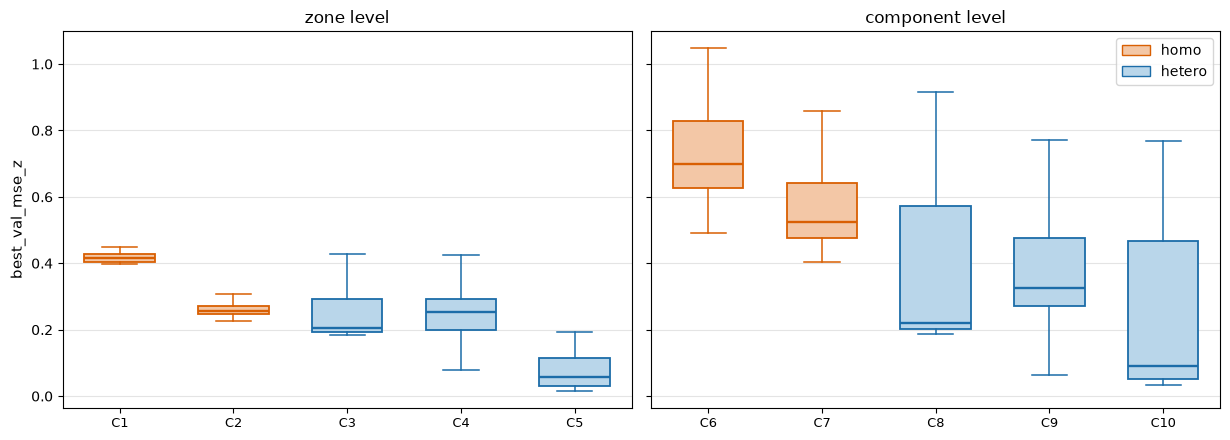

all_runs_validation_mse_scatter_split_zones_components -> outputs/paper/figures/all_runs_validation_mse_scatter_split_zones_components.png


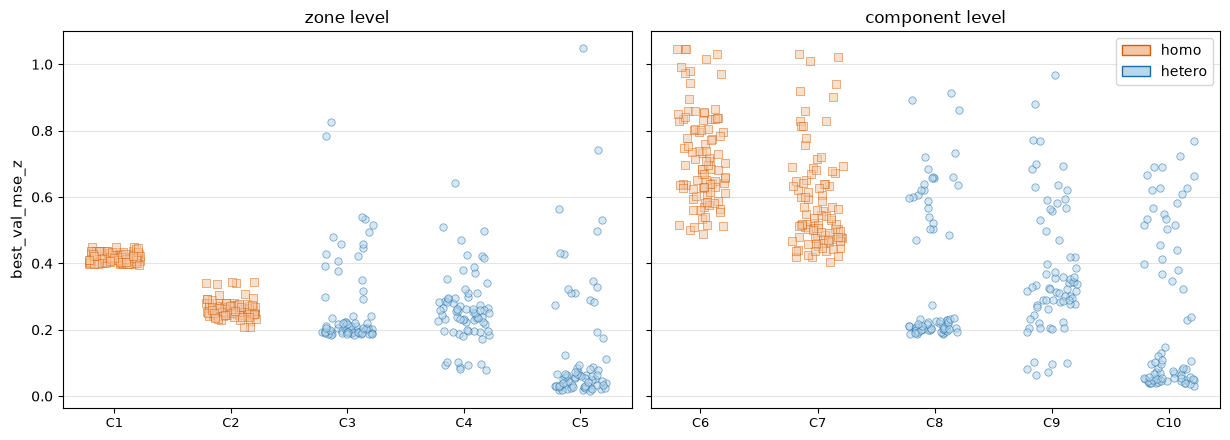


per-configuration spread of validation MSE across all 816 stable runs:


,n,best,median,worst
config_name,,,,
C1_zone_homo_no_weather,96,0.396,0.416,0.449
C2_zone_homo_graph_weather,96,0.209,0.256,0.345
C3_zone_hetero_no_weather,72,0.185,0.204,0.826
C4_zone_hetero_building_weather,72,0.078,0.252,0.641
C5_zone_hetero_external_weather,72,0.016,0.058,1.048
C6_component_homo_no_weather,96,0.490,0.699,1.047
C7_component_homo_graph_weather,96,0.404,0.526,1.031
C8_component_hetero_no_weather,72,0.187,0.219,0.915
C9_component_hetero_building_weather,72,0.065,0.324,0.969


,config_id,config_name,model_family,model_key,n_runs,validation_mse_z_mean,validation_mse_z_std,validation_mse_z_min
0,C1,C1_zone_homo_no_weather,GCN,gcn,24,0.4094,0.0123,0.3967
1,C1,C1_zone_homo_no_weather,GIN,gin_mean,24,0.4201,0.0117,0.4009
2,C1,C1_zone_homo_no_weather,GIN,gin_set2set,24,0.4255,0.0138,0.4012
3,C1,C1_zone_homo_no_weather,GraphSAGE,sage_attn,24,0.4156,0.0144,0.3963
4,C2,C2_zone_homo_graph_weather,GCN,gcn,24,0.2586,0.0130,0.2421
5,C2,C2_zone_homo_graph_weather,GIN,gin_mean,24,0.2739,0.0281,0.2418
6,C2,C2_zone_homo_graph_weather,GIN,gin_set2set,24,0.2690,0.0232,0.2401
7,C2,C2_zone_homo_graph_weather,GraphSAGE,sage_attn,24,0.2475,0.0285,0.2091
8,C3,C3_zone_hetero_no_weather,HeteroGIN,heterogin,24,0.2371,0.1312,0.1856
9,C3,C3_zone_hetero_no_weather,HeteroSAGE,heterosage,24,0.2003,0.0130,0.1851


In [6]:
validation_runs_table = R.summarise_validation_runs(stable)
validation_runs_table.to_csv(TABLES_DIR / "validation_summary_all_runs_config_model_key.csv", index=False)

for name, figure in (
    ("all_runs_validation_mse_boxplot_split_zones_components", P.plot_all_runs_boxplot(stable)),
    ("all_runs_validation_mse_scatter_split_zones_components", P.plot_all_runs_scatter(stable)),
):
    written = P.save_figure(figure, FIGURES_DIR / f"{name}.png", dpi=FIGURE_DPI, formats=FIGURE_FORMATS)
    print(f"{name} -> {display_path(written[0])}")
    show(figure)

print(f"\nper-configuration spread of validation MSE across all {len(stable)} stable runs:")
display(
    stable.assign(best_val_mse_z=lambda d: pd.to_numeric(d["best_val_mse_z"], errors="coerce"))
        .groupby("config_name")["best_val_mse_z"]
        .agg(n="size", best="min", median="median", worst="max")
        .reindex(sorted(stable["config_name"].unique(), key=sort_key))
        .round(3)
)

validation_runs_table.head(12).round(4)

## What weather buys, and how it should enter the graph

Each configuration pair differs in exactly one thing:
C1→C2 and C6→C7 attach a graph-level vector, C3→C4 and C8→C9 widen the building node, C3→C5 and
C8→C10 add a weather node with its own edges.

The figure groups *validation* loss by weather variant, keeping the test set out of this design
comparison.

**Outputs**
- `outputs/paper/figures/all_runs_validation_mse_grouped_by_weather.png`
- `weather_table`, the change in test R² for each pair

**Used functions**
`plot_weather_effect`, `weather_effect`

figure -> outputs/paper/figures/all_runs_validation_mse_grouped_by_weather.png


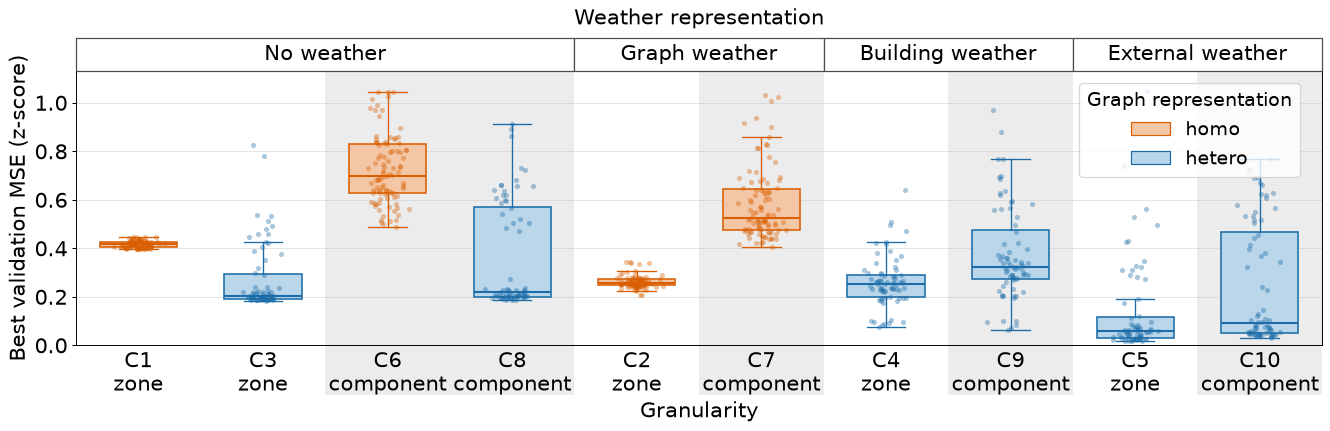

weather improves every pair: True; largest gain +0.167 R2, smallest +0.068


,level,graph_kind,baseline,with_weather,weather_enters_as,r2_baseline,r2_with_weather,delta_r2
0,zone,homo,C1,C2,graph-level vector,0.5820,0.7486,0.1666
1,component,homo,C6,C7,graph-level vector,0.5095,0.5774,0.0679
2,zone,hetero,C3,C4,building-node features,0.8347,0.9318,0.0971
3,component,hetero,C8,C9,building-node features,0.8311,0.9361,0.1050
4,zone,hetero,C3,C5,weather node,0.8347,0.9851,0.1504
5,component,hetero,C8,C10,weather node,0.8311,0.9708,0.1397


In [7]:
figure = P.plot_weather_effect(stable)
written = P.save_figure(figure, FIGURES_DIR / "all_runs_validation_mse_grouped_by_weather.png",
                        dpi=FIGURE_DPI, formats=FIGURE_FORMATS)
print(f"figure -> {display_path(written[0])}")
show(figure)

weather_table = R.weather_effect(best)
weather_table.to_csv(TABLES_DIR / "weather_variant_effect.csv", index=False)

gains = weather_table["delta_r2"]
print(f"weather improves every pair: {bool((gains > 0).all())}; "
      f"largest gain {gains.max():+.3f} R2, smallest {gains.min():+.3f}")

weather_table.round(4)

## Does the validation ranking survive across the search?

This comparison uses validation MSE only. It compares the validation-selected run with the median
variant for each configuration.

**Outputs**
- `ranking`, validation-selected-run against median-run order

**Used functions**
`configuration_ranking`, `rank_agreement`

In [8]:
ranking = R.configuration_ranking(stable, best)
ranking.to_csv(TABLES_DIR / "configuration_ranking.csv", index=False)
agreement = R.rank_agreement(ranking)
print(f"\nbest-run against median-run ordering: Spearman rho = {agreement:.3f}, "
      f"{int((ranking['rank_shift'] != 0).sum())} of {len(ranking)} configurations move")

ranking[["config_id", "selected_model", "selected_validation_mse", "median_validation_mse",
         "rank_by_selected_validation", "rank_by_median_validation", "rank_shift"]].round(3)


best-run against median-run ordering: Spearman rho = 0.842, 5 of 10 configurations move


,config_id,selected_model,selected_validation_mse,median_validation_mse,rank_by_selected_validation,rank_by_median_validation,rank_shift
0,C5,heterogin,0.016,0.058,1,1,0
1,C10,heterogin,0.032,0.091,2,2,0
2,C9,heterosage,0.065,0.324,3,7,4
3,C4,heterosage,0.078,0.252,4,5,1
4,C3,heterosage,0.185,0.204,5,3,-2
5,C8,heterogin,0.187,0.219,6,4,-2
6,C2,sage_attn,0.209,0.256,7,6,-1
7,C1,sage_attn,0.396,0.416,8,8,0
8,C7,sage_attn,0.404,0.526,9,9,0
9,C6,sage_attn,0.490,0.699,10,10,0


# The selected runs in detail

## Did they train, or only score?

Training and validation loss for each selected run, with the kept epoch marked. A run that scored
well while still improving, or while its validation loss pulled away from its training loss, supports
a weaker claim than one that converged.

**Outputs**: `outputs/paper/figures/best_runs_training_curves_grid.png`.

**Used functions**
`plot_training_curves`

figure -> outputs/paper/figures/best_runs_training_curves_grid.png


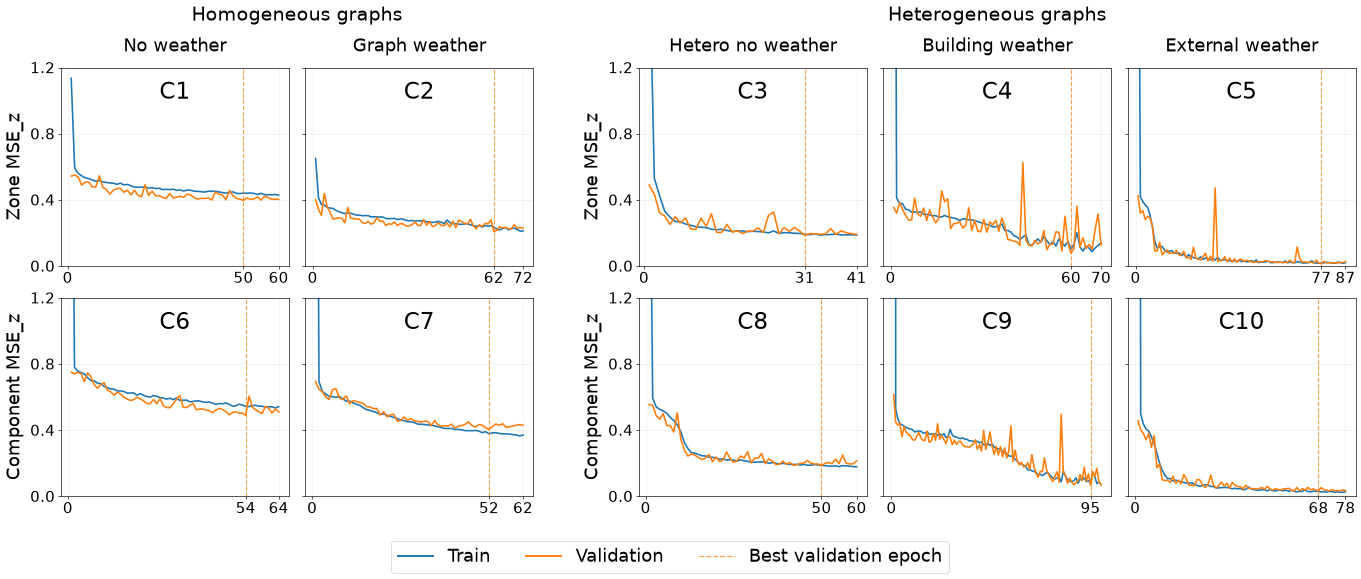

selected runs that stopped early: 9 of 10


,config_id,model_key,best_val_epoch,epochs_ran,best_val_mse_z
0,C1,sage_attn,50,60,0.3963
1,C2,sage_attn,62,72,0.2091
2,C3,heterosage,31,41,0.1851
3,C4,heterosage,60,70,0.0779
4,C5,heterogin,77,87,0.0164
5,C6,sage_attn,54,64,0.4898
6,C7,sage_attn,52,62,0.4043
7,C8,heterogin,50,60,0.1865
8,C9,heterosage,95,100,0.0649
9,C10,heterogin,68,78,0.0320


In [9]:
figure = P.plot_training_curves(best, RUNS_DIR)
written = P.save_figure(figure, FIGURES_DIR / "best_runs_training_curves_grid.png",
                        dpi=FIGURE_DPI, formats=FIGURE_FORMATS)
print(f"figure -> {display_path(written[0])}")
show(figure)

stopped_early = best[pd.to_numeric(best["epochs_ran"], errors="coerce") < EXPERIMENT_MAX_EPOCHS]
print(f"selected runs that stopped early: {len(stopped_early)} of {len(best)}")

best[["config_id", "model_key", "best_val_epoch", "epochs_ran", "best_val_mse_z"]].round(4)

## Predicted against measured

Shows where along the range each model is accurate, which R² alone does not. Hexbin density over
the 2,652 test buildings.

**Outputs**: `outputs/paper/figures/best_runs_test_predictions_scatter.png`.

**Used functions**
`plot_test_predictions`

figure -> outputs/paper/figures/best_runs_test_predictions_scatter.png


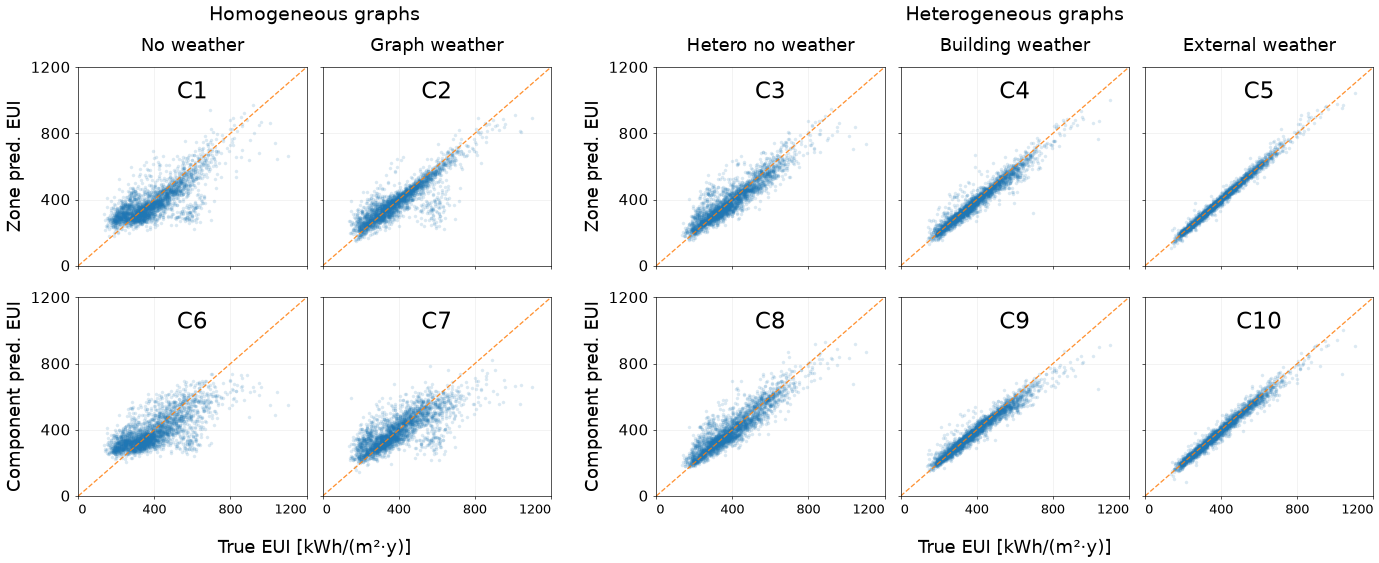

,config_id,model_key,mae_raw,median_abs_err_raw,p95_abs_err_raw
0,C1,sage_attn,66.04,49.67,202.65
1,C2,sage_attn,44.20,26.76,159.18
2,C3,heterosage,41.07,29.68,119.04
3,C4,heterosage,24.35,16.42,73.43
4,C5,heterogin,12.16,8.88,33.98
5,C6,sage_attn,73.68,57.13,206.77
6,C7,sage_attn,64.23,42.69,201.31
7,C8,heterogin,41.95,30.68,121.06
8,C9,heterosage,24.18,16.76,71.89
9,C10,heterogin,16.65,11.98,47.86


In [10]:
figure = P.plot_test_predictions(best, RUNS_DIR)
written = P.save_figure(figure, FIGURES_DIR / "best_runs_test_predictions_scatter.png",
                        dpi=FIGURE_DPI, formats=FIGURE_FORMATS)
print(f"figure -> {display_path(written[0])}")
show(figure)

errors = []
for _, row in best.iterrows():
    predictions = R.load_predictions(RUNS_DIR, row["run_dir"])
    errors.append({
        "config_id": resolve(row["config_name"]).id,
        "model_key": row["model_key"],
        "mae_raw": float(predictions["err_raw"].abs().mean()),
        "median_abs_err_raw": float(predictions["err_raw"].abs().median()),
        "p95_abs_err_raw": float(predictions["err_raw"].abs().quantile(0.95)),
    })
error_table = pd.DataFrame(errors)
error_table.to_csv(TABLES_DIR / "best_runs_error_distribution.csv", index=False)

error_table.round(2)

## Does it put the better building first?

A surrogate used to shortlist designs is judged by ordering more than by error: it is useful if it
ranks the options the way a simulation would. For the best zone-level and component-level candidates
this reports Spearman's ρ, Kendall's τ, and the share of building pairs ordered the same way as
EnergyPlus — over every pair, and over pairs at least `MINIMUM_EUI_GAP` apart, since two buildings a
few kWh apart are close to a coin toss for any model.

**Outputs**: `building_order`, written to `outputs/paper/tables/building_order_fidelity.csv`.

**Used functions**
`building_order_fidelity`

In [11]:
building_order = R.building_order_fidelity(
    best, RUNS_DIR, configs=BUILDING_ORDER_CONFIGS, minimum_eui_gap=MINIMUM_EUI_GAP
)
building_order.to_csv(TABLES_DIR / "building_order_fidelity.csv", index=False)

for row in building_order.itertuples():
    print(f"{row.config_id}*: Spearman rho {row.spearman_rho:.3f}, "
          f"{100 * row.pairs_ordered_correctly:.1f}% of {row.pairs:,} pairs ordered correctly, "
          f"{100 * row.pairs_apart_ordered_correctly:.1f}% of pairs at least {row.min_gap_kwh_per_m2:g} apart")

building_order.round(4)

C5*: Spearman rho 0.993, 96.6% of 3,515,206 pairs ordered correctly, 99.3% of pairs at least 25 apart
C10*: Spearman rho 0.987, 95.3% of 3,515,206 pairs ordered correctly, 98.5% of pairs at least 25 apart


,config_id,model_key,n_test_buildings,spearman_rho,kendall_tau,pairs,pairs_ordered_correctly,min_gap_kwh_per_m2,pairs_apart,pairs_apart_ordered_correctly
0,C5,heterogin,2652,0.9929,0.9311,3515206,0.9656,25.0,3139898,0.9934
1,C10,heterogin,2652,0.9872,0.9051,3515206,0.9525,25.0,3139898,0.9851


# What it cost

## Simulating the dataset against training its surrogates

Four panels: EnergyPlus wall-clock time and SQL output size per model, then total search time and
deployable model size per configuration, with each selected model marked.

Training times are comparable when the runs come from one machine; each `run_meta.json` records its
hardware. Prediction time is an **upper bound**: the gap between a
run's last checkpoint and its predictions file, plus two seconds of timestamp resolution, divided by
the number of test buildings.

**Inputs**: `SIMULATION_TIMING`, the model packages under `outputs/GNNruns/`.

**Outputs**
- `outputs/paper/figures/computational_costs.png`
- `cost_summary`, `cost`, `prediction_bound`, written to `outputs/paper/tables/`

**Used functions**
`load_simulation_timing`, `model_package_sizes`, `prediction_time_upper_bound`,
`computational_cost_summary`, `plot_computational_cost`, `training_cost`

figure -> outputs/paper/figures/computational_costs.png


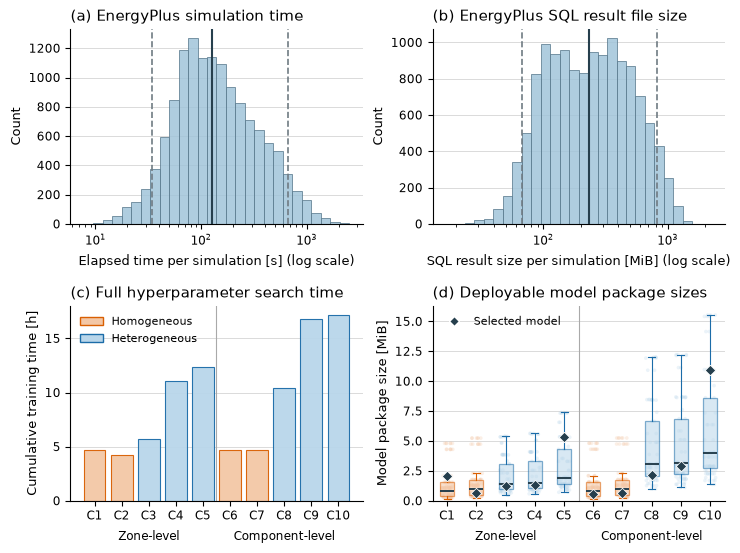

,quantity,value
0,EnergyPlus simulations timed,"13,259 of 13,260"
1,"EnergyPlus time, total",774.7 h
2,"EnergyPlus time, median per model",126.2 s
3,"EnergyPlus SQL output, total",3.92 TiB
4,"GNN search, total training time",91.8 h over 816 runs
5,GNN training as share of simulation time,11.85 %
6,"model packages, total",2.04 GiB
7,model packages as share of SQL output,0.051 %
8,"prediction, upper bound per building",1.810 ms (mean over selected runs)
9,"prediction, upper bound for all 13,260 models",24.0 s


In [12]:
simulation = R.load_simulation_timing(SIMULATION_TIMING)
packages = R.model_package_sizes(stable, RUNS_DIR)
prediction_bound = R.prediction_time_upper_bound(best, RUNS_DIR)
cost = R.training_cost(stable)
cost_summary = R.computational_cost_summary(stable, simulation, packages, prediction_bound, n_models=N_MODELS)

figure = P.plot_computational_cost(simulation, stable, packages, best)
written = P.save_figure(figure, FIGURES_DIR / "computational_costs.png", dpi=FIGURE_DPI, formats=FIGURE_FORMATS)
print(f"figure -> {display_path(written[0])}")
show(figure)

for name, frame in (("computational_cost_summary", cost_summary), ("training_cost", cost),
                    ("prediction_time_upper_bound", prediction_bound)):
    frame.to_csv(TABLES_DIR / f"{name}.csv", index=False)

cost_summary

## How large the models are

Trainable parameters of every run, rebuilt from the architecture its `run_meta.json` records and one
graph of its configuration. Counts depend on input width, which is fixed per configuration. The ranges
per model family are the appendix table.

**Outputs**: `parameter_ranges`, and every run's count in `outputs/paper/tables/`.

**Used functions**
`parameter_counts`, `parameter_count_ranges`

In [13]:
parameters = R.parameter_counts(stable, RUNS_DIR, GRAPHS_ROOT)
parameter_ranges = R.parameter_count_ranges(parameters)
parameters.to_csv(TABLES_DIR / "parameter_counts_by_run.csv", index=False)
parameter_ranges.to_csv(TABLES_DIR / "parameter_count_ranges.csv", index=False)

print(f"{len(parameters)} models rebuilt; trainable parameters from "
      f"{parameters['trainable_parameters'].min():,} to {parameters['trainable_parameters'].max():,}")

parameter_ranges

816 models rebuilt; trainable parameters from 37,121 to 4,048,641


,model_family,model_key,runs,configurations,trainable_min,trainable_median,trainable_max
0,GCN,gcn,96,4,37121,99329.0,331009
1,GIN,gin_mean,96,4,70145,132993.0,462593
2,GIN,gin_set2set,96,4,284161,750465.0,1373697
3,GraphSAGE,sage_attn,96,4,73986,168322.0,603906
4,HeteroGIN,heterogin,144,6,256641,741633.0,4048641
5,HeteroSAGE,heterosage,144,6,221825,750465.0,4028422
6,R-GCN-like,rgcn,144,6,122753,470277.0,2252038


### Check what was written

Every artefact the manuscript draws on, including the two all-run validation figures, and whether it was
written.

**Outputs**: `artefacts`.

In [14]:
artefacts = pd.DataFrame(
    [
        {"kind": path.parent.name, "file": path.name,
         "size_kb": round(path.stat().st_size / 1024, 1), "path": display_path(path)}
        for path in sorted(list(TABLES_DIR.glob("*.csv")) + list(FIGURES_DIR.glob("*.*")))
    ]
)

expected = {
    # the tables the manuscript and its appendix draw on
    "test_summary_best_runs.csv", "validation_summary_all_runs_config_model_key.csv",
    "configuration_ranking.csv", "building_order_fidelity.csv",
    "weather_variant_effect.csv", "best_runs_error_distribution.csv",
    "computational_cost_summary.csv", "training_cost.csv", "prediction_time_upper_bound.csv",
    "parameter_count_ranges.csv", "parameter_counts_by_run.csv",
    # the figures, under the names the manuscript embeds
    "all_runs_validation_mse_grouped_by_weather.png", "best_runs_training_curves_grid.png",
    "best_runs_test_predictions_scatter.png", "computational_costs.png",
    # validation figures that show the spread of every run
    "all_runs_validation_mse_boxplot_split_zones_components.png",
    "all_runs_validation_mse_scatter_split_zones_components.png",
}
missing = sorted(expected - set(artefacts["file"]))
if missing:
    print(f"MISSING {len(missing)} artefact(s): {missing}")
else:
    print(f"All {len(expected)} expected artefacts written to {display_path(PAPER_DIR)}.")

artefacts

All 17 expected artefacts written to outputs/paper.


,kind,file,size_kb,path
0,figures,all_runs_validation_mse_boxplot_split_zones_co...,14.0,outputs/paper/figures/all_runs_validation_mse_...
1,figures,all_runs_validation_mse_boxplot_split_zones_co...,90.7,outputs/paper/figures/all_runs_validation_mse_...
2,figures,all_runs_validation_mse_grouped_by_weather.pdf,34.9,outputs/paper/figures/all_runs_validation_mse_...
3,figures,all_runs_validation_mse_grouped_by_weather.png,434.9,outputs/paper/figures/all_runs_validation_mse_...
4,figures,all_runs_validation_mse_scatter_split_zones_co...,28.9,outputs/paper/figures/all_runs_validation_mse_...
5,figures,all_runs_validation_mse_scatter_split_zones_co...,446.7,outputs/paper/figures/all_runs_validation_mse_...
6,figures,best_runs_test_predictions_scatter.png,2596.6,outputs/paper/figures/best_runs_test_predictio...
7,figures,best_runs_test_predictions_scatter.svg,1754.5,outputs/paper/figures/best_runs_test_predictio...
8,figures,best_runs_training_curves_grid.png,1003.3,outputs/paper/figures/best_runs_training_curve...
9,figures,best_runs_training_curves_grid.svg,129.3,outputs/paper/figures/best_runs_training_curve...


---

The pipeline ends here. `outputs/paper/` holds the tables and figures.